# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

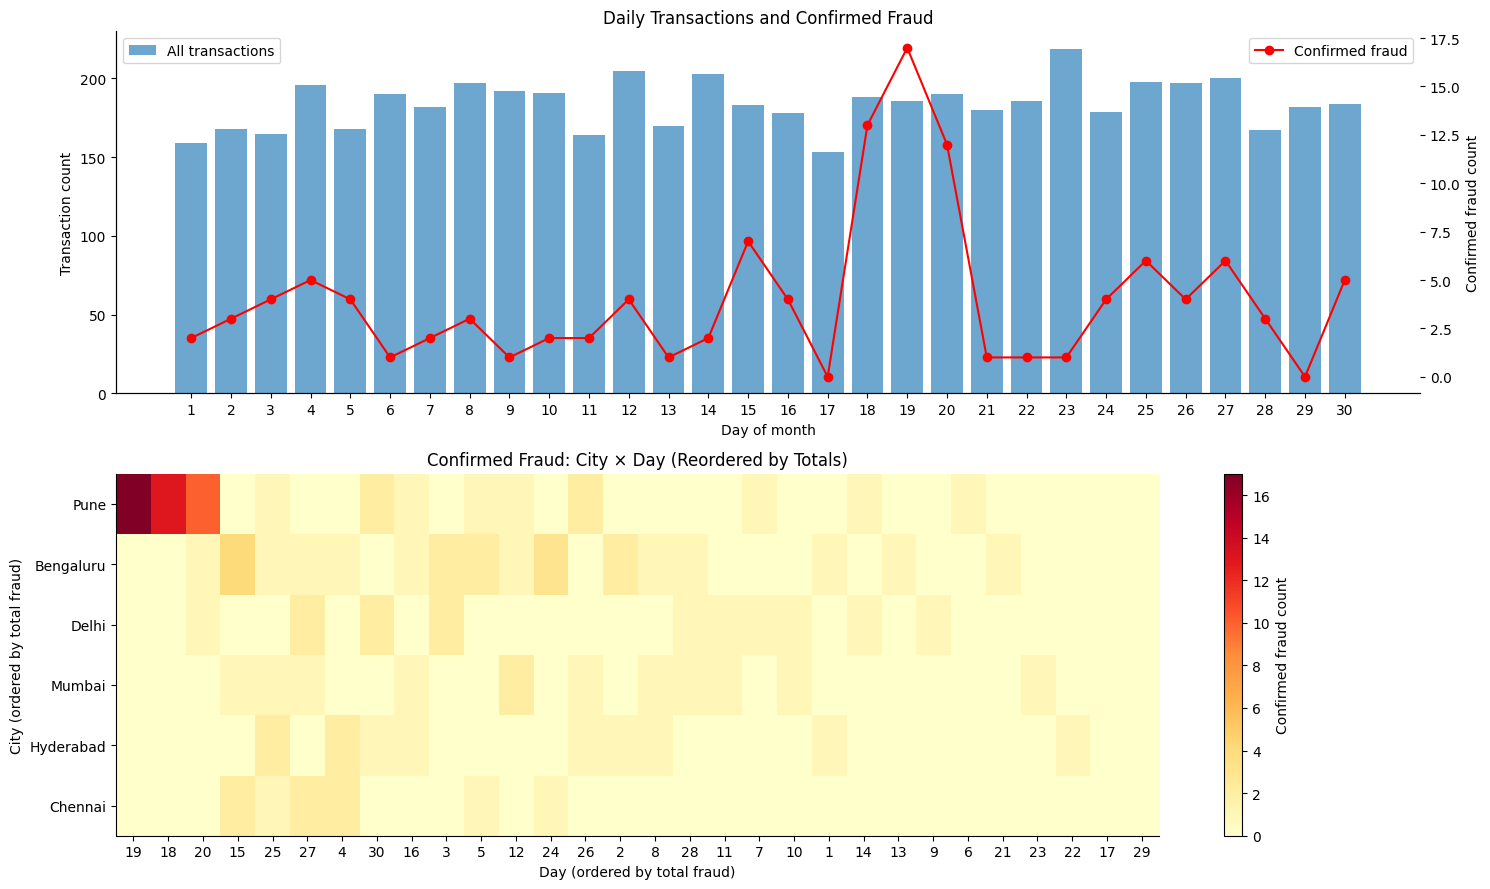

Top city-day cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
Chennai    4       2
Bengaluru  3       2
Hyderabad  25      2
Pune       26      2
Chennai    15      2
dtype: int64


In [2]:

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# TODO 1: Daily transaction counts and confirmed fraud
daily = tx.groupby("day").size()
daily_fraud = tx.groupby("day")["is_fraud"].sum()

axes[0].bar(daily.index, daily.values, alpha=0.65,
            label="All transactions")
axes[0].set_xlabel("Day of month")
axes[0].set_ylabel("Transaction count")
axes[0].set_title("Daily Transactions and Confirmed Fraud")
axes[0].set_xticks(range(1, 31))
ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values,
         color="red", marker="o", label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud count")
axes[0].legend(loc="upper left")
ax2.legend(loc="upper right")

# TODO 2: City x day confirmed-fraud matrix
city_day = tx.pivot_table(
    index="city", columns="day", values="is_fraud",
    aggfunc="sum", fill_value=0
)

city_order = city_day.sum(axis=1).sort_values(
    ascending=False
).index
day_order = city_day.sum(axis=0).sort_values(
    ascending=False
).index

heat = city_day.loc[city_order, day_order]

im = axes[1].imshow(heat.values, aspect="auto", cmap="YlOrRd")
axes[1].set_title("Confirmed Fraud: City × Day (Reordered by Totals)")
axes[1].set_xlabel("Day (ordered by total fraud)")
axes[1].set_ylabel("City (ordered by total fraud)")
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
fig.colorbar(im, ax=axes[1], label="Confirmed fraud count")

plt.tight_layout()
plt.show()

# TODO 3: City-day cells with the most fraud
top_cells = city_day.stack().sort_values(ascending=False)
print("Top city-day cells:")
print(top_cells.head(10))


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview revealed a concentration of confirmed fraud in Pune during days 18–20, which would be difficult to identify from an alert list sorted only by detector score. The daily chart showed when fraud increased, while the reordered city-by-day heatmap exposed the spatial and temporal concentration. This uses Shneiderman's “overview first” principle and the reordered matrix technique, which makes important patterns stand out visually.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

Night-time transactions: 225
Far-from-home transactions: 238
Both conditions: 59
Confirmed fraud in subset: 51


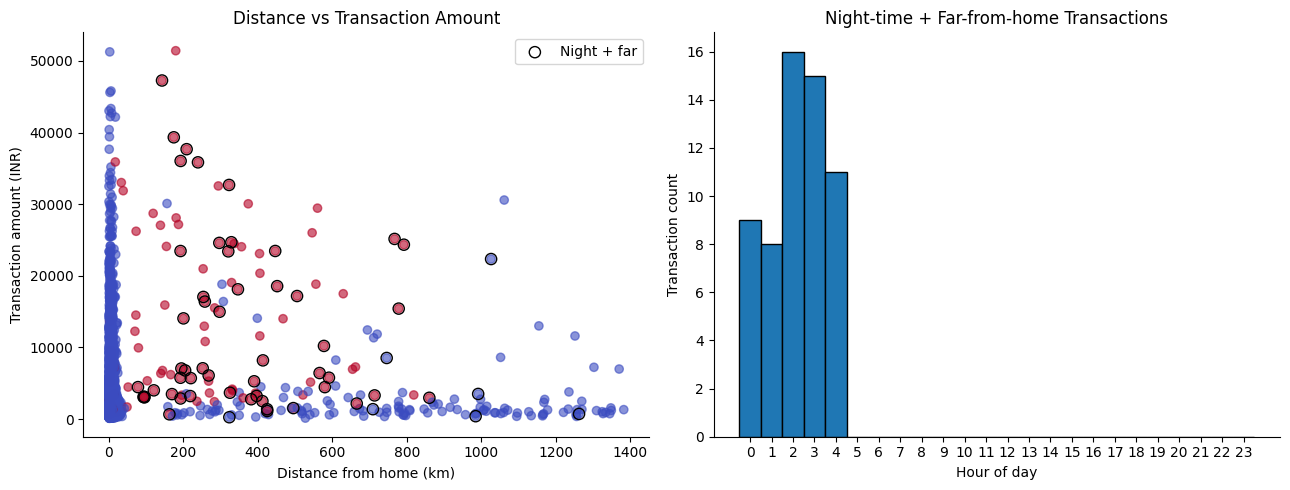

In [4]:

# Task 2: Night-time and far-from-home transactions

night = (tx["hour"] >= 0) & (tx["hour"] < 5)
far = tx["distance_from_home_km"] > 50
night_far = night & far

subset = tx.loc[night_far].copy()

print("Night-time transactions:", int(night.sum()))
print("Far-from-home transactions:", int(far.sum()))
print("Both conditions:", len(subset))
print("Confirmed fraud in subset:", int(subset["is_fraud"].sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# View 1: Distance vs transaction amount
axes[0].scatter(
    tx["distance_from_home_km"], tx["amount_inr"],
    c=tx["is_fraud"], cmap="coolwarm", alpha=0.6
)
axes[0].scatter(
    subset["distance_from_home_km"], subset["amount_inr"],
    facecolors="none", edgecolors="black", s=65,
    label="Night + far"
)
axes[0].set_xlabel("Distance from home (km)")
axes[0].set_ylabel("Transaction amount (INR)")
axes[0].set_title("Distance vs Transaction Amount")
axes[0].legend()

# View 2: Transaction hours
axes[1].hist(
    subset["hour"],
    bins=np.arange(-0.5, 24.5, 1),
    edgecolor="black"
)
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Transaction count")
axes[1].set_title("Night-time + Far-from-home Transactions")
axes[1].set_xticks(range(24))

plt.tight_layout()
plt.show()


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

Linked views allow analysts to examine the same transactions from different perspectives. Selecting night-time, far-from-home transactions in one view helps identify their transaction amounts and distribution across hours in the other view. This reduces the need to search through separate charts manually and supports coordinated analysis. However, a transaction that occurs at night or far from home is not necessarily fraudulent, so the selected records should be investigated rather than automatically classified as fraud.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

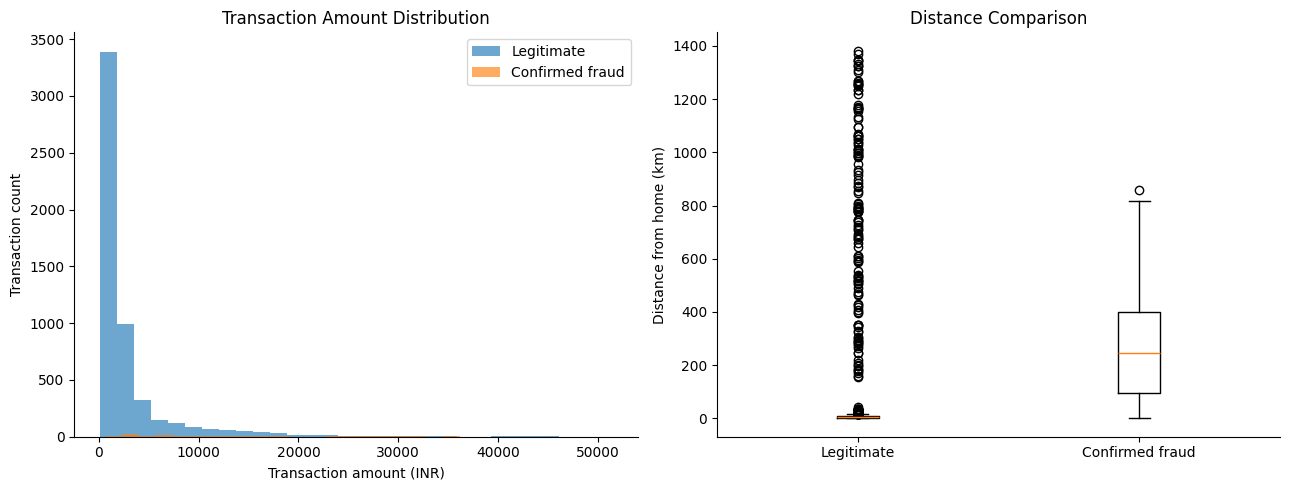

Legitimate transactions: 5400
Confirmed fraud transactions: 120
Median legitimate amount: 1339.0
Median fraud amount: 7193.0


In [5]:

# Task 3: Compare transaction amount distributions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Amount distribution: legitimate vs confirmed fraud
legit = tx.loc[tx["is_fraud"] == 0, "amount_inr"]
fraud = tx.loc[tx["is_fraud"] == 1, "amount_inr"]

axes[0].hist(legit, bins=30, alpha=0.65, label="Legitimate")
axes[0].hist(fraud, bins=30, alpha=0.65, label="Confirmed fraud")
axes[0].set_xlabel("Transaction amount (INR)")
axes[0].set_ylabel("Transaction count")
axes[0].set_title("Transaction Amount Distribution")
axes[0].legend()

# Compare distance from home
axes[1].boxplot(
    [tx.loc[tx["is_fraud"] == 0, "distance_from_home_km"],
     tx.loc[tx["is_fraud"] == 1, "distance_from_home_km"]],
    tick_labels=["Legitimate", "Confirmed fraud"]
)
axes[1].set_ylabel("Distance from home (km)")
axes[1].set_title("Distance Comparison")

plt.tight_layout()
plt.show()

print("Legitimate transactions:", len(legit))
print("Confirmed fraud transactions:", len(fraud))
print("Median legitimate amount:", legit.median())
print("Median fraud amount:", fraud.median())


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

Comparing the distributions helps identify differences between legitimate transactions and confirmed fraud. Histograms show how transaction amounts are distributed, while boxplots compare typical distances and reveal unusually large values. However, these features alone cannot reliably determine whether a transaction is fraudulent because legitimate transactions can also involve high amounts or long distances. The visualizations should support investigation rather than replace the fraud detector or confirmation process.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.0567,0.9500,0.1069
1,0.10,1167,111,1056,9,0.0951,0.9250,0.1725
2,0.15,785,110,675,10,0.1401,0.9167,0.2431
3,0.20,596,106,490,14,0.1779,0.8833,0.2961
4,0.25,471,105,366,15,0.2229,0.8750,0.3553
5,0.30,401,104,297,16,0.2594,0.8667,0.3992
6,0.35,355,104,251,16,0.2930,0.8667,0.4379
7,0.40,319,104,215,16,0.3260,0.8667,0.4738
8,0.45,283,104,179,16,0.3675,0.8667,0.5161
9,0.50,260,101,159,19,0.3885,0.8417,0.5316


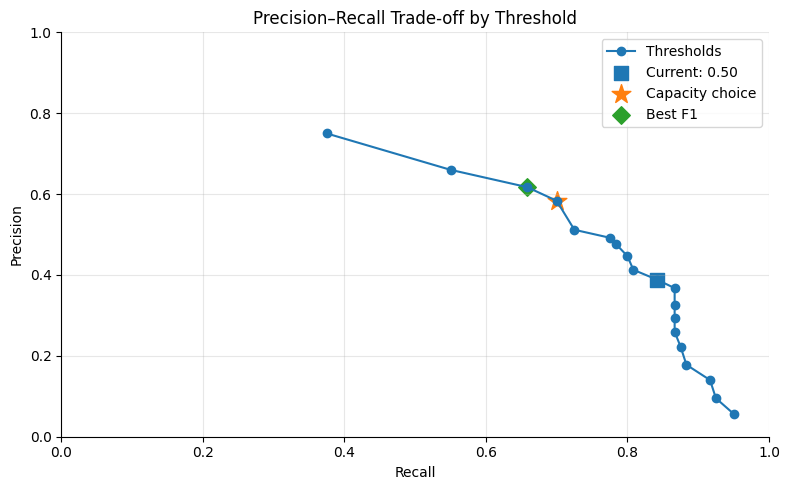

Recommendation: threshold 0.80 produces 144 alerts, with precision 0.583 and recall 0.700, within the 150-alert capacity.


In [6]:

rows = []

# TODO 1: evaluate thresholds from 0.05 to 0.95
y_true = tx["is_fraud"].astype(bool)

for threshold in np.arange(0.05, 1.00, 0.05):
    predicted = tx["detector_score"] >= threshold

    tp = int((predicted & y_true).sum())
    fp = int((predicted & ~y_true).sum())
    fn = int((~predicted & y_true).sum())
    alerts = int(predicted.sum())

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "threshold": round(float(threshold), 2),
        "alerts": alerts,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: capacity-constrained and best-F1 thresholds
eligible = pr[pr["alerts"] <= 150]
capacity_choice = eligible.sort_values(
    ["recall", "threshold"],
    ascending=[False, True]
).iloc[0]

best_f1 = pr.sort_values(
    ["F1", "threshold"],
    ascending=[False, True]
).iloc[0]

display(pr.round(4))

# TODO 3: precision-recall curve
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pr["recall"], pr["precision"], marker="o",
        label="Thresholds")

current = pr.loc[pr["threshold"] == 0.50].iloc[0]

ax.scatter(current["recall"], current["precision"],
           marker="s", s=100, label="Current: 0.50")

ax.scatter(capacity_choice["recall"],
           capacity_choice["precision"],
           marker="*", s=200, label="Capacity choice")

ax.scatter(best_f1["recall"], best_f1["precision"],
           marker="D", s=80, label="Best F1")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Trade-off by Threshold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# TODO 4: recommendation
print(
    f"Recommendation: threshold {capacity_choice['threshold']:.2f} "
    f"produces {int(capacity_choice['alerts'])} alerts, "
    f"with precision {capacity_choice['precision']:.3f} "
    f"and recall {capacity_choice['recall']:.3f}, "
    f"within the 150-alert capacity."
)


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make the final threshold decision with support from the model and the visual analytics dashboard. The capacity-constrained threshold of 0.80 produces 144 alerts, with 70% recall and 58.33% precision, while the best-F1 threshold of 0.85 produces 128 alerts with a slightly higher F1 score but lower recall. Choosing between these thresholds requires balancing investigator capacity against the cost of missed fraud. Visual analytics keeps a human in the loop because metrics alone cannot determine the operational cost of false positives and false negatives. The Head of Fraud Ops must consider business priorities, review capacity and risk before approving the threshold.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [8]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# Select transactions using their existing dataframe index
transaction_selector = widgets.Dropdown(
    options=[(str(i), i) for i in tx.index],
    description="Transaction:",
    layout=widgets.Layout(width="400px")
)

output = widgets.Output()

def inspect_transaction(change=None):
    with output:
        clear_output(wait=True)

        selected_index = transaction_selector.value
        row = tx.loc[selected_index]

        print("SELECTED TRANSACTION")
        display(row.to_frame(name="Value"))

        # Find other transactions from the same city
        related = tx[tx["city"] == row["city"]].copy()
        related = related.sort_values(
            "detector_score", ascending=False
        ).head(10)

        # Display only columns that actually exist
        wanted = [
            "timestamp", "city", "hour", "amount_inr",
            "distance_from_home_km", "detector_score", "is_fraud"
        ]
        available = [c for c in wanted if c in related.columns]

        print("\nTOP 10 TRANSACTIONS IN THE SAME CITY")
        display(related[available])

transaction_selector.observe(
    inspect_transaction, names="value"
)

display(transaction_selector, output)
inspect_transaction()


Dropdown(description='Transaction:', layout=Layout(width='400px'), options=(('0', 0), ('1', 1), ('2', 2), ('3'…

Output()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

An interactive investigator tool allows analysts to select a suspicious transaction and inspect its details without searching through the entire dataset manually. Showing related transactions from the same city helps investigators identify possible patterns and connections. However, similarity does not prove fraud, and the detector score should not be treated as a definitive judgment. The final decision should be based on transaction evidence and appropriate human review.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Pune transactions on days 18-20: 107
Confirmed fraud on days 18-20: 40


,transactions,confirmed_fraud,mean_score
day,,,
18,32,13,0.381978
19,41,17,0.425329
20,34,10,0.383509



Fraud rate on days 18-20: 37.38%
Fraud rate on other Pune days: 1.85%


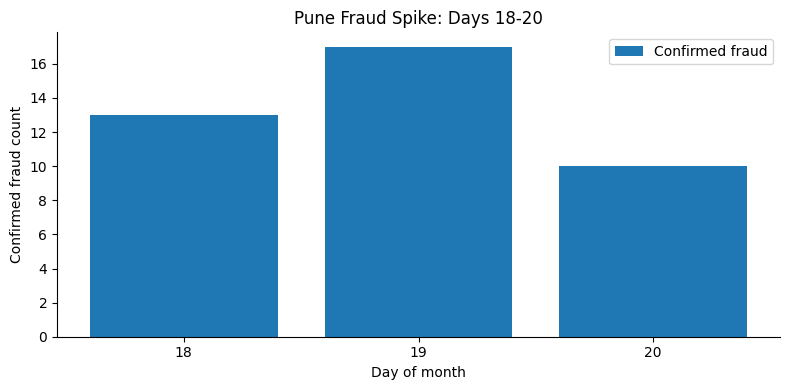

In [9]:

# Task 6: Investigate the suspected Pune fraud spike

pune = tx[tx["city"].str.lower() == "pune"].copy()

# Focus on days 18-20
spike = pune[pune["day"].isin([18, 19, 20])].copy()

print("Pune transactions on days 18-20:", len(spike))
print("Confirmed fraud on days 18-20:", int(spike["is_fraud"].sum()))

# Daily breakdown
daily_spike = spike.groupby("day").agg(
    transactions=("is_fraud", "size"),
    confirmed_fraud=("is_fraud", "sum"),
    mean_score=("detector_score", "mean")
)

display(daily_spike)

# Compare with other Pune days
other_days = pune[~pune["day"].isin([18, 19, 20])]

print("\nFraud rate on days 18-20:",
      f"{spike['is_fraud'].mean():.2%}")

print("Fraud rate on other Pune days:",
      f"{other_days['is_fraud'].mean():.2%}")

# Visual comparison
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    daily_spike.index.astype(str),
    daily_spike["confirmed_fraud"],
    label="Confirmed fraud"
)

ax.set_xlabel("Day of month")
ax.set_ylabel("Confirmed fraud count")
ax.set_title("Pune Fraud Spike: Days 18-20")
ax.legend()

plt.tight_layout()
plt.show()


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

The overview heatmap identified a concentration of confirmed fraud in Pune during days 18–20, with the highest count on day 19. I would investigate the transactions from this period by examining their timestamps, amounts, detector scores and distances from home, and compare them with Pune transactions from other days. This helps determine whether the spike reflects unusual transaction behaviour or a broader change in activity. The visual pattern is a useful starting point, but it does not establish a cause or prove that the transactions are connected. Further investigation is needed before drawing conclusions.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month, PayKart recorded 5,520 transactions, including 120 confirmed fraud cases, with a concentration of 40 fraud cases in Pune on days 18–20, peaking at 17 on day 19. I recommend raising the detector threshold from 0.50 to **0.80**, which produces 144 alerts within the monthly capacity of 150, with 58.33% precision and 70% recall; the Head of Fraud Ops should approve the final trade-off because missed fraud and false alerts have different operational costs. The first interactive view to build should be the investigator scatter plot with selection, filtering and hover tooltips, supporting dynamic queries and details-on-demand. The interface should be optimised to meet the lecture's 0.1-second response-time target, using indexing or data reduction if necessary. Finally, implement a **human-in-the-loop feedback loop** that incorporates investigators' confirmed outcomes and false-positive/false-negative reviews into future detector evaluation and improvement.